# Panelled Shock?Outbreak Visuals

This notebook recreates the coefficient and inclusion-weight plots produced by the automated pipeline. For each timing window (lags, leads, contemporaneous) the figures are combined into multi-panel layouts with labelled subplots for the five retained scopes (a) Global, (b) Africa, (c) Asia, (d) America, and (e) Europe.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

plt.style.use('seaborn-v0_8-whitegrid')

In [7]:
RESULTS_PATH = Path('..') / 'outputs' / 'tables' / 'model_averaged_estimates.csv'
OUTPUT_DIR = Path('..') / 'outputs' / 'figures' / 'panels'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SCOPES = ['Global', 'Africa', 'Asia', 'America', 'Europe']
DATASET_TITLES = {
    'lags': 'Prior shocks',
    'leads': 'Subsequent shocks',
    'contemp': 'Concurrent shocks',
}
PANEL_LABELS = {scope: f"({chr(97 + idx)}) {scope}" for idx, scope in enumerate(SCOPES)}
results = pd.read_csv(RESULTS_PATH)
results['label'] = results['label'].astype(str)
results["label"] = results["label"].str.replace(r"\s*\(.*\)", "", regex=True)

In [8]:
def plot_coefficients_panel(dataset: str, save: bool = True):
    subset = results[results['dataset'] == dataset].copy()
    if subset.empty:
        raise ValueError(f'No records available for dataset={dataset}')

    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=False)
    axes_flat = axes.flatten()

    interval_color = '#3A7CA5'
    point_color = '#1B4079'

    for idx, ax in enumerate(axes_flat):
        if idx >= len(SCOPES):
            ax.axis('off')
            continue

        scope = SCOPES[idx]
        scope_df = subset[subset['scope'] == scope].copy().sort_values('estimate')
        if scope_df.empty:
            ax.axis('off')
            ax.text(0.5, 0.5, 'No eligible models', ha='center', va='center', fontsize=10)
            continue

        y_pos = np.arange(len(scope_df))
        ax.hlines(y_pos, scope_df['ci_lower'], scope_df['ci_upper'], color=interval_color, linewidth=2)
        ax.scatter(scope_df['estimate'], y_pos, color=point_color, s=35, zorder=3)
        ax.axvline(0, color='#9AA0A6', linestyle='--', linewidth=1)

        ax.set_yticks(y_pos)
        ax.set_yticklabels(scope_df['label'], fontsize=8)
        ax.set_ylim(-0.5, len(scope_df) - 0.5)
        ax.set_title(PANEL_LABELS[scope], loc='left', fontsize=11, fontweight='bold')
        ax.set_xlabel('Model-averaged coefficient', fontsize=9)
        ax.tick_params(axis='x', labelsize=8)

        ax.grid(True, axis='x', color='#E0E3E7', linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.spines['left'].set_color('#C1C7CD')
        ax.spines['bottom'].set_color('#C1C7CD')

    #fig.suptitle(f"{DATASET_TITLES[dataset]} | Coefficients", fontsize=15, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.94))

    if save:
        out_path = OUTPUT_DIR / f"{dataset}_coefficients_panels.png"
        fig.savefig(out_path, dpi=300, bbox_inches='tight')
    return fig


In [9]:
def plot_inclusion_panel(dataset: str, save: bool = True):
    subset = results[results['dataset'] == dataset].copy()
    if subset.empty:
        raise ValueError(f'No records available for dataset={dataset}')

    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=False)
    axes_flat = axes.flatten()

    bar_color = '#2F6690'

    for idx, ax in enumerate(axes_flat):
        if idx >= len(SCOPES):
            ax.axis('off')
            continue

        scope = SCOPES[idx]
        scope_df = subset[subset['scope'] == scope].copy().sort_values('inclusion_weight')
        if scope_df.empty:
            ax.axis('off')
            ax.text(0.5, 0.5, 'No eligible models', ha='center', va='center', fontsize=10)
            continue

        y_pos = np.arange(len(scope_df))
        ax.barh(y_pos, scope_df['inclusion_weight'], color=bar_color, edgecolor='none')
        ax.set_yticks(y_pos)
        ax.set_yticklabels(scope_df['label'], fontsize=8)
        ax.set_xlim(0, 1)
        ax.set_title(PANEL_LABELS[scope], loc='left', fontsize=11, fontweight='bold')
        ax.set_xlabel('Akaike inclusion weight', fontsize=9)
        ax.tick_params(axis='x', labelsize=8)

        ax.grid(True, axis='x', color='#E0E3E7', linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.spines['left'].set_color('#C1C7CD')
        ax.spines['bottom'].set_color('#C1C7CD')

    #fig.suptitle(f"{DATASET_TITLES[dataset]} | Inclusion weights", fontsize=15, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.94))

    if save:
        out_path = OUTPUT_DIR / f"{dataset}_inclusion_panels.png"
        fig.savefig(out_path, dpi=300, bbox_inches='tight')
    return fig


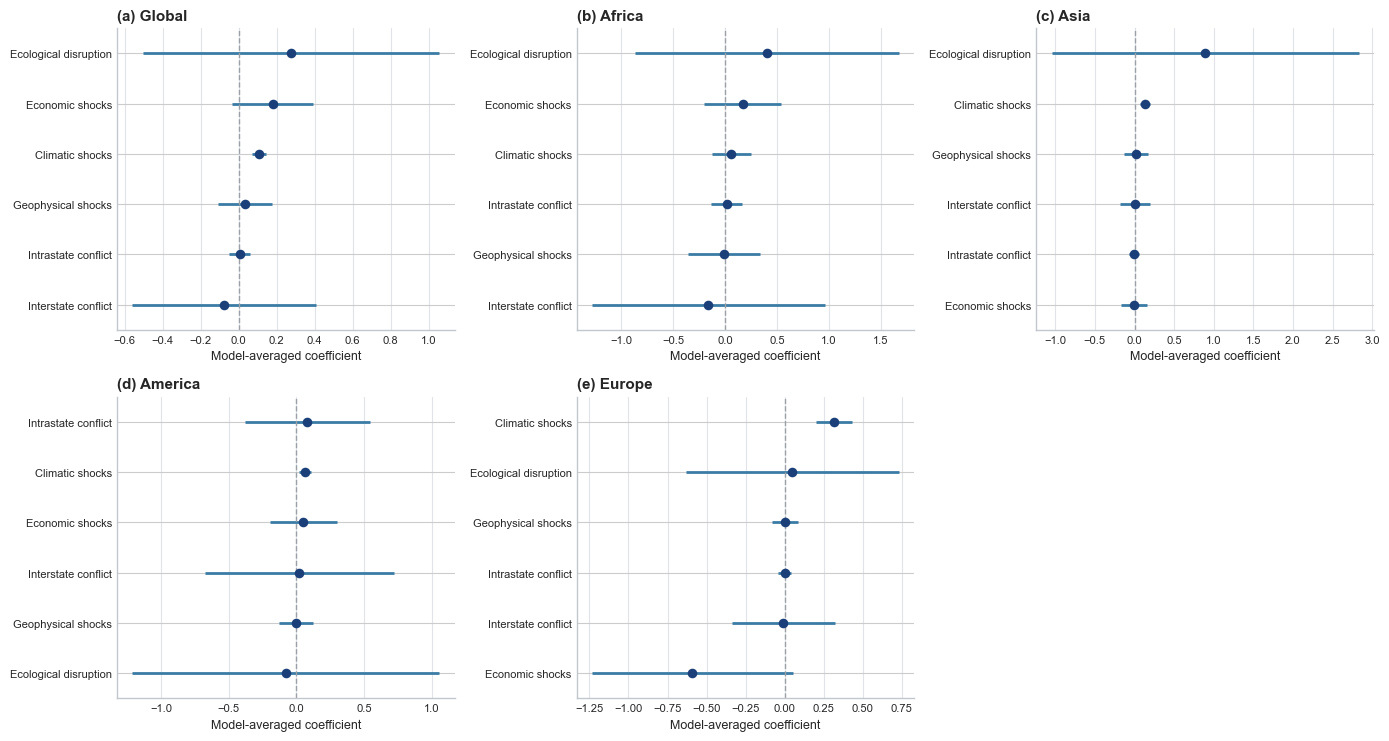

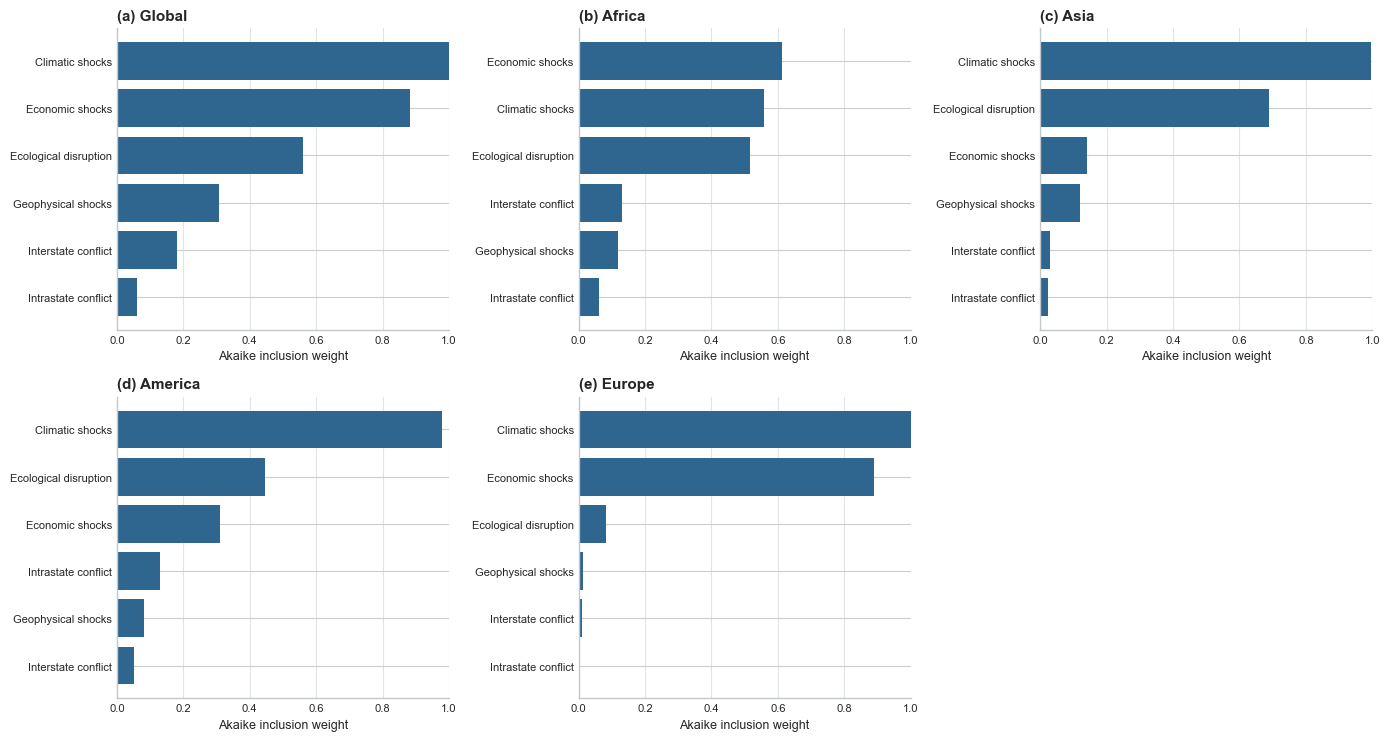

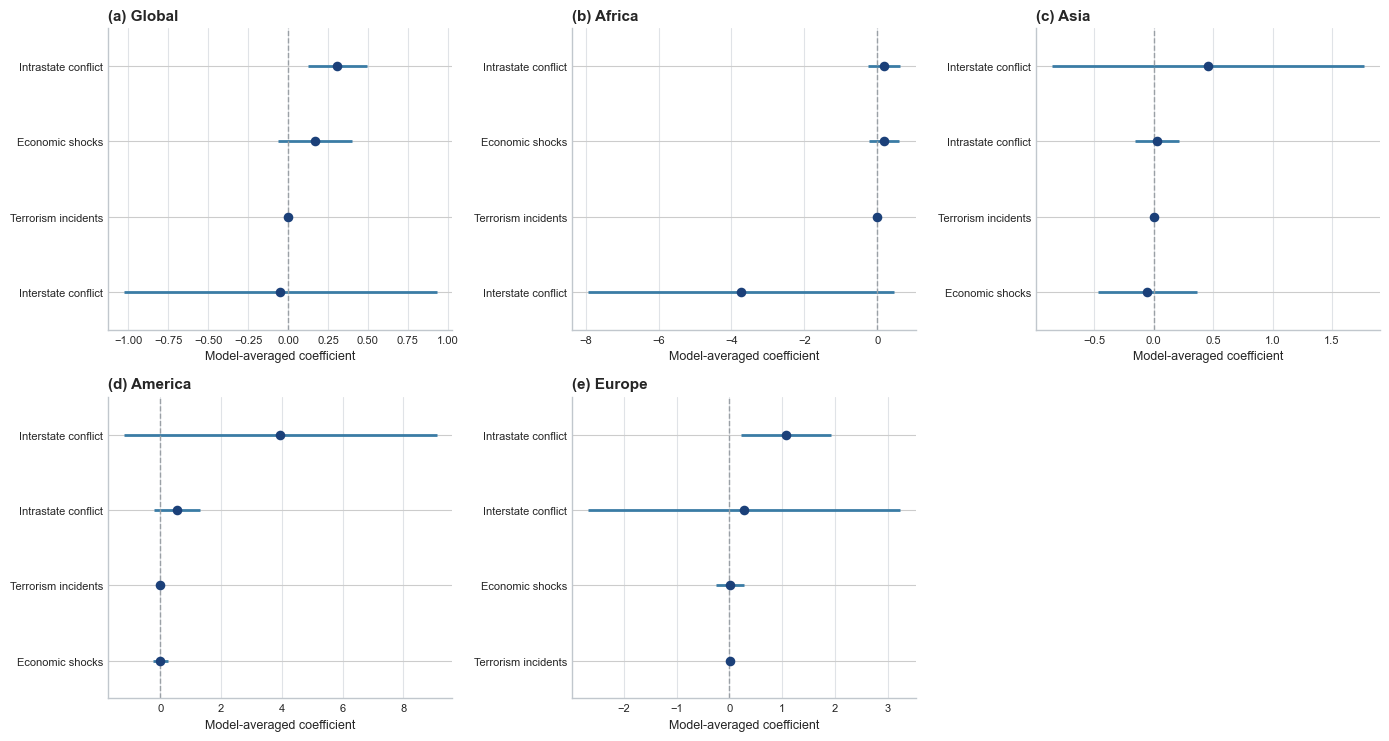

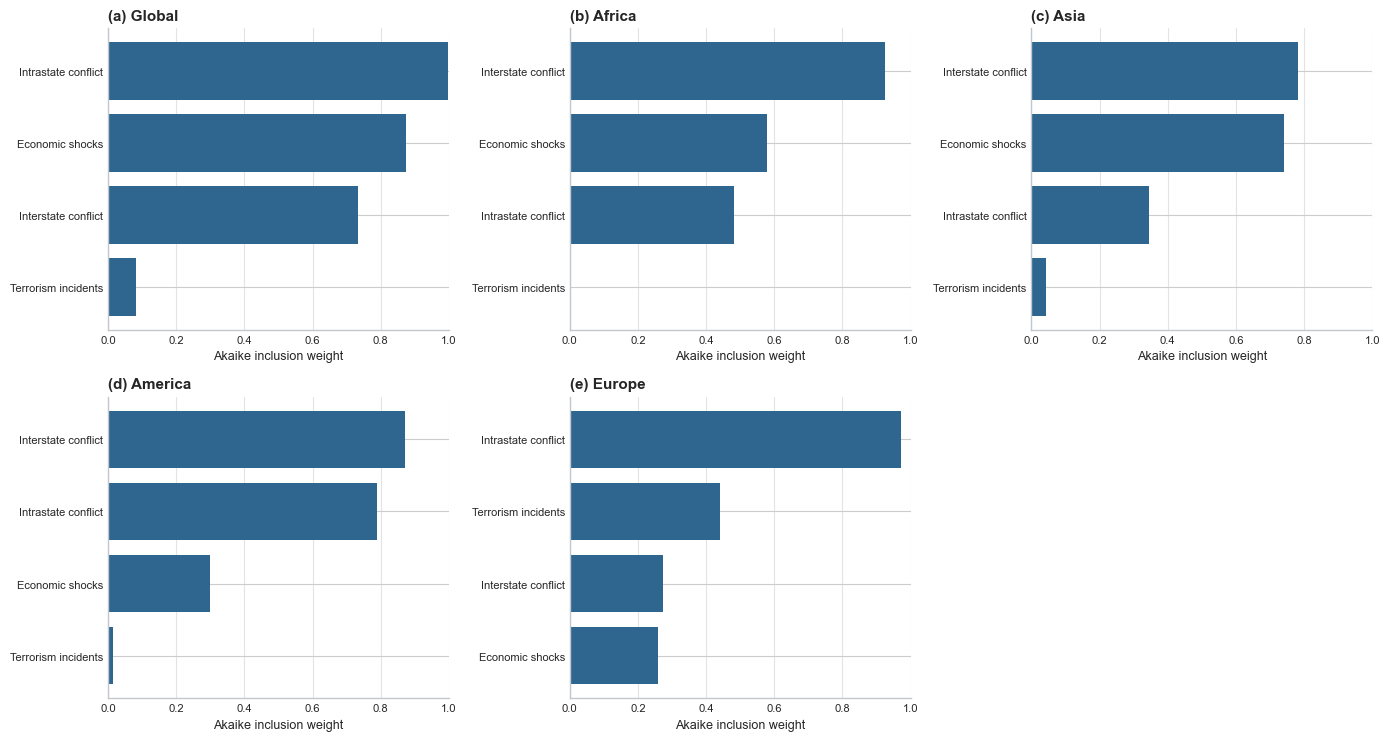

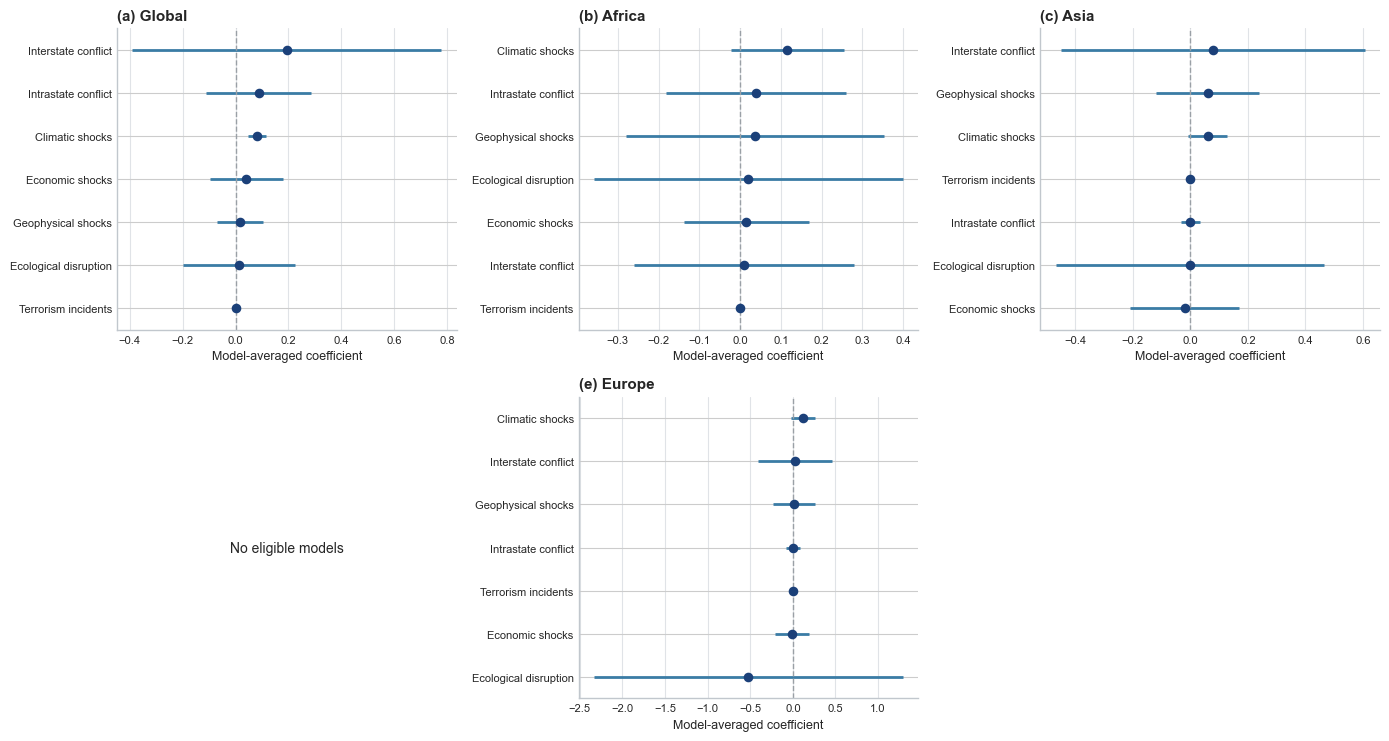

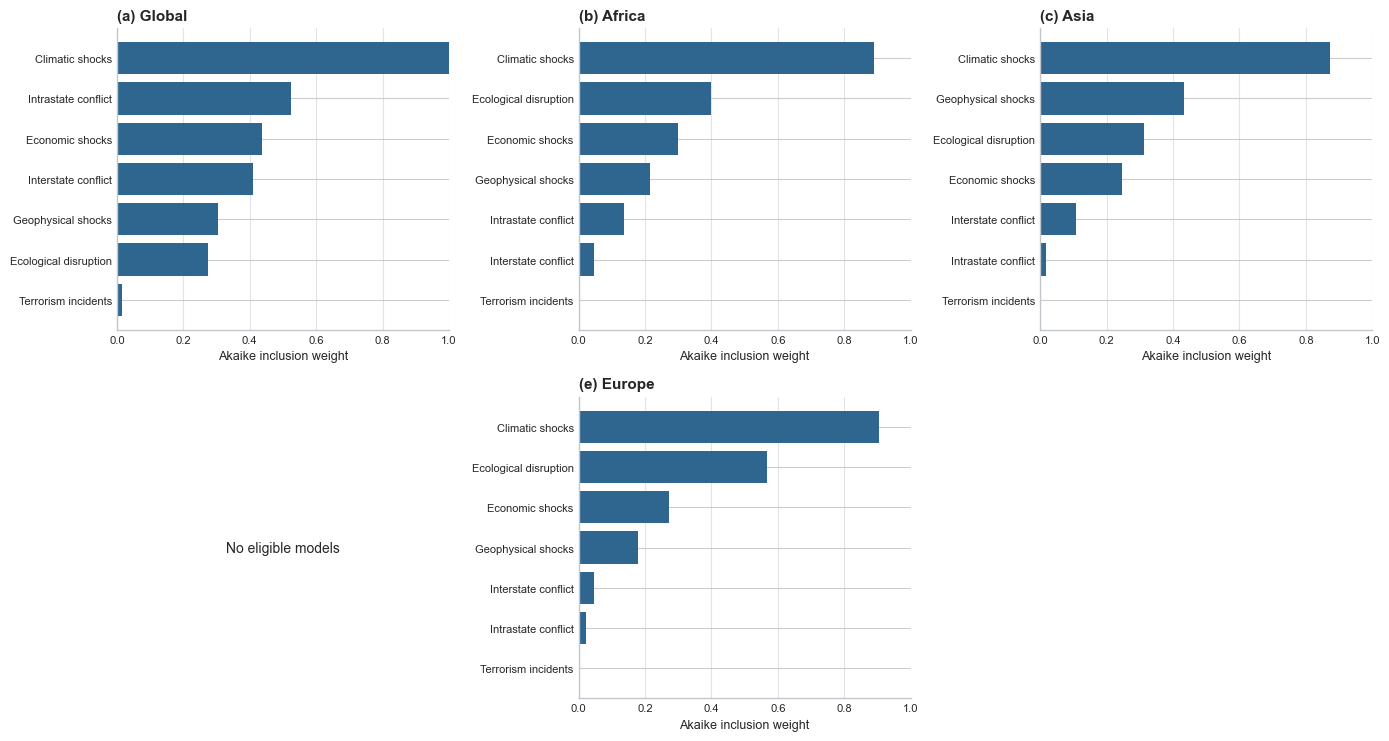

In [10]:
for dataset in DATASET_TITLES:
    _ = plot_coefficients_panel(dataset)
    plt.show()
    _ = plot_inclusion_panel(dataset)
    plt.show()
